# Keşifsel Veri Analizi (EDA)

Bu not defteri `data/bank_customers.csv` dosyasını inceler. Amaç, model eğitmeden önce veriyi tanımak:

1. Veri nasıl görünüyor?
2. Eksik veya tekrar eden kayıt var mı?
3. Sınıflar dengeli mi (kaç müşteri ayrılmış)?
4. Hangi özellikler müşteri kaybıyla ilişkili?
5. Ön işleme adımları veri sızıntısı olmadan nasıl çalışıyor?

> Tüm veri **kurgusaldır**, gerçek müşterilere ait değildir.

In [1]:
import sys
from pathlib import Path

# Not defteri 'notebooks/' klasöründe çalıştığı için proje kök klasörünü import yoluna ekliyoruz
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.preprocessing import (
    load_data, data_quality_report, clean_data,
    split_data, build_preprocessor, get_feature_names,
    NUMERIC_FEATURES, BINARY_FEATURES,
)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (8, 4)

## 1. Veriyi yükle

In [2]:
df_raw = load_data()
print("Satır x sütun:", df_raw.shape)
df_raw.head()

Satır x sütun: (10000, 14)


,CustomerID,Age,Gender,Geography,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Complaints,CustomerSegment,Exited
0,C106253,51,Male,Marmara,694.0,4,0.00,1,1,1,187994.20,1,Premium,0
1,C104685,33,Male,Marmara,606.0,1,0.00,1,1,0,55492.60,0,Standard,0
2,C101732,40,Male,Marmara,850.0,1,99536.27,2,1,0,49030.34,0,Gold,0
3,C104743,39,Male,Marmara,531.0,8,71210.31,1,1,1,141910.00,0,Gold,0
4,C104522,44,Male,Marmara,592.0,2,66736.42,1,1,1,34225.50,0,Standard,0


In [3]:
# Sütun türleri ve sayısal özet
display(df_raw.dtypes.to_frame("tür").T)
df_raw.describe().round(1)

,CustomerID,Age,Gender,Geography,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Complaints,CustomerSegment,Exited
tür,str,int64,str,str,float64,int64,float64,int64,int64,int64,float64,int64,str,int64


,Age,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Complaints,Exited
count,10000.0,9849.0,10000.0,10000.0,10000.0,10000.0,10000.0,9856.0,10000.0,10000.0
mean,40.0,649.1,5.0,74777.8,1.7,0.7,0.5,110860.7,0.4,0.2
std,10.8,89.6,3.2,55495.0,0.7,0.5,0.5,52109.6,0.7,0.4
min,18.0,300.0,0.0,0.0,1.0,0.0,0.0,20006.9,0.0,0.0
25%,33.0,589.0,2.0,0.0,1.0,0.0,0.0,65663.7,0.0,0.0
50%,40.0,649.0,5.0,82022.3,2.0,1.0,1.0,111371.6,0.0,0.0
75%,47.0,710.0,8.0,116473.2,2.0,1.0,1.0,156669.3,1.0,0.0
max,84.0,850.0,10.0,267415.7,4.0,1.0,1.0,199988.2,5.0,1.0


## 2. Veri kalitesi: eksik ve tekrar kayıtlar

In [4]:
report = data_quality_report(df_raw)
print("Tekrar eden satır :", report["n_duplicate_rows"])
print("Tekrar eden ID    :", report["n_duplicate_ids"])
print("Eksik değerler    :", report["missing_values"])

Tekrar eden satır : 25
Tekrar eden ID    : 25
Eksik değerler    : {'Geography': 156, 'CreditScore': 151, 'EstimatedSalary': 144}


Üretici betiğe bilinçli olarak ~%1,5 eksik değer ve 25 tekrar kayıt koymuştuk. Rapor bunları buldu.

- **Tekrar kayıtlar** `clean_data` ile silinecek.
- **Eksik değerler** burada doldurulmayacak. Doldurma işlemi Pipeline içinde, yalnızca eğitim verisinden öğrenilen değerlerle yapılacak (veri sızıntısını önlemek için).

In [5]:
df = clean_data(df_raw)
print("Temizlik sonrası satır sayısı:", len(df))
print("Kalan tekrar kayıt:", df.duplicated().sum())

Temizlik sonrası satır sayısı: 9975
Kalan tekrar kayıt: 0


## 3. Sınıf dengesi

`Exited = 1` ayrılan, `Exited = 0` kalan müşteri demektir.

             müşteri  oran %
Exited                      
Kaldı (0)       7994    80.1
Ayrıldı (1)     1981    19.9


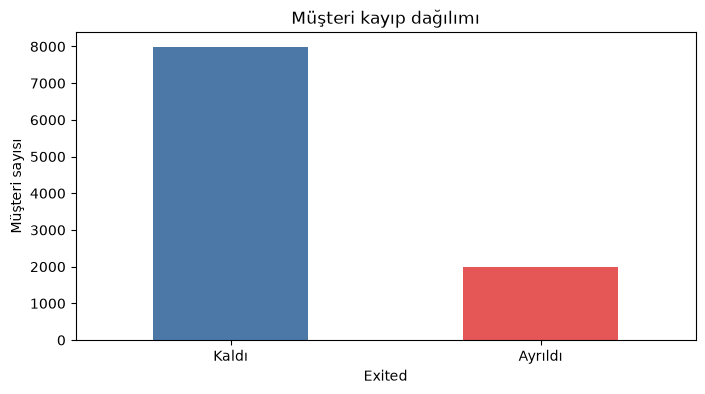

In [6]:
counts = df["Exited"].value_counts().sort_index()
rates = (counts / counts.sum() * 100).round(1)
print(pd.DataFrame({"müşteri": counts, "oran %": rates}).rename(index={0: "Kaldı (0)", 1: "Ayrıldı (1)"}))

ax = counts.rename(index={0: "Kaldı", 1: "Ayrıldı"}).plot(kind="bar", color=["#4C78A8", "#E45756"])
ax.set_title("Müşteri kayıp dağılımı")
ax.set_ylabel("Müşteri sayısı")
ax.tick_params(axis="x", rotation=0)
plt.show()

**Yorum:** Veri dengesiz, ayrılanlar yaklaşık beşte bir (%20). Bu durumda model "herkes kalır" derse bile %80 doğruluk alır. Bu yüzden **Accuracy tek başına yanıltıcıdır**; Recall, F1 ve ROC-AUC'ye bakacağız. Dengesizliği eğitimde `class_weight='balanced'` ile ele alacağız.

## 4. Sayısal özelliklerin dağılımı (ayrılan ve kalan müşteriler)

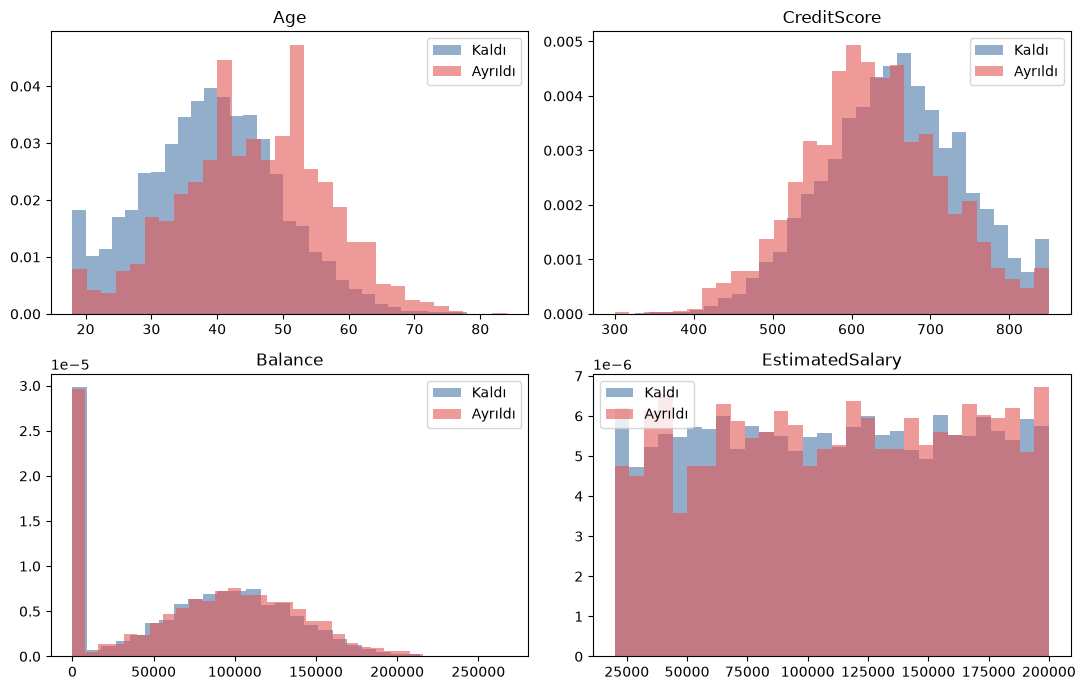

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ["Age", "CreditScore", "Balance", "EstimatedSalary"]):
    ax.hist(df.loc[df["Exited"] == 0, col].dropna(), bins=30, alpha=0.6, density=True, label="Kaldı", color="#4C78A8")
    ax.hist(df.loc[df["Exited"] == 1, col].dropna(), bins=30, alpha=0.6, density=True, label="Ayrıldı", color="#E45756")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

**Yorum:** Yaş dağılımında ayrılanlar belirgin şekilde sağa (yaşlıya) kayıyor. Diğer değişkenlerde fark daha küçük.

## 5. Gruplara göre müşteri kaybı oranı

Kırmızı kesikli çizgi genel ortalamadır (~%20). Çizginin üstündeki gruplar riskli sayılır.

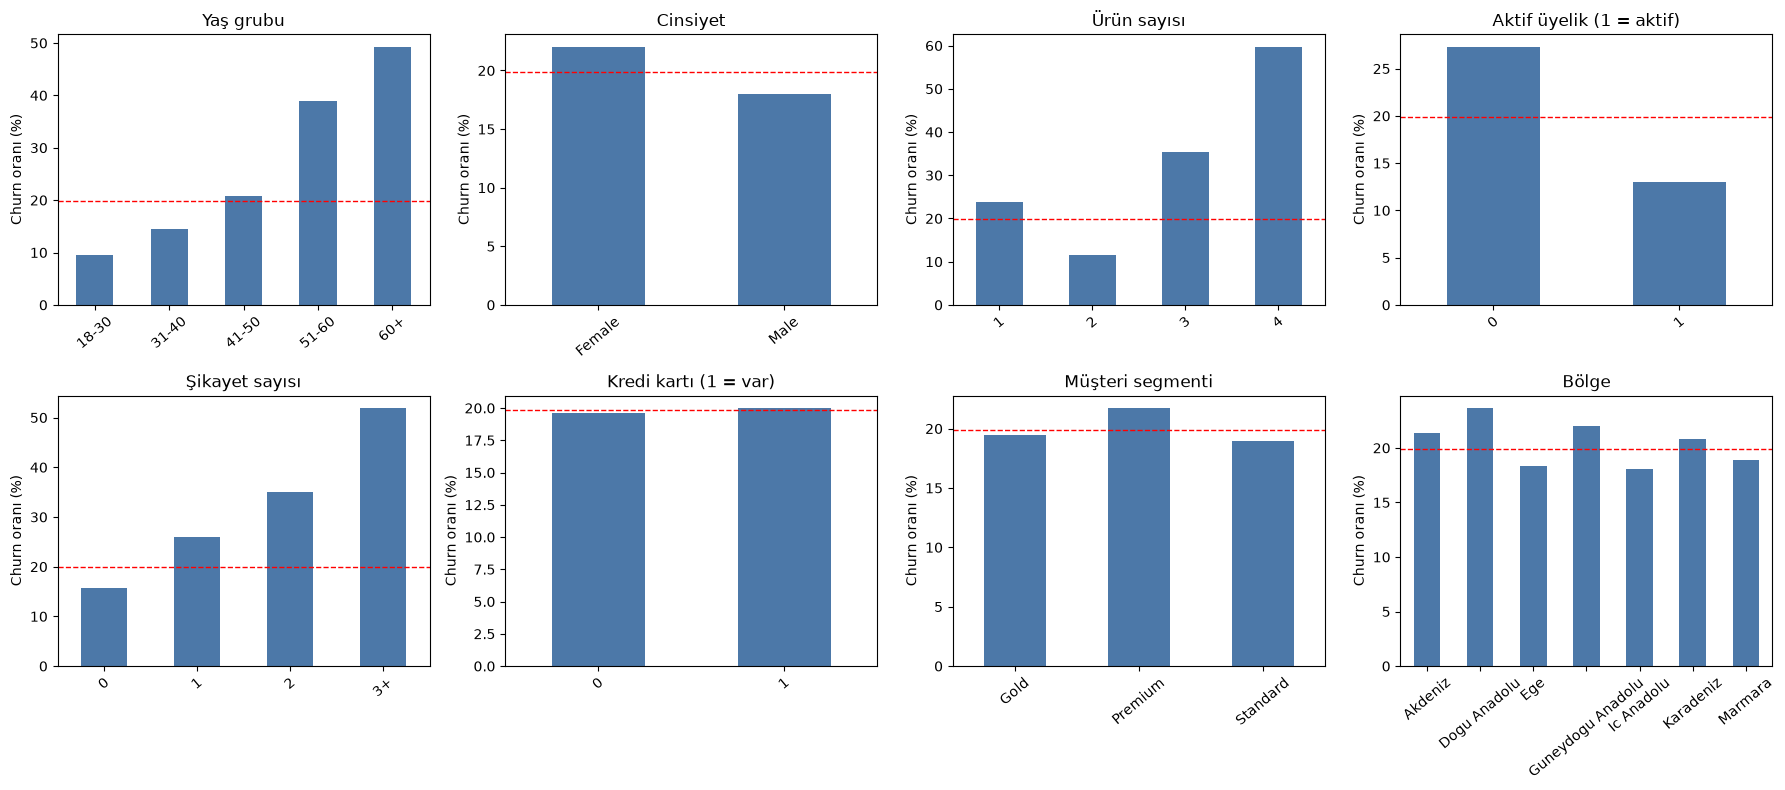

In [8]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[17, 30, 40, 50, 60, 100],
                        labels=["18-30", "31-40", "41-50", "51-60", "60+"])
df["ComplaintsGroup"] = df["Complaints"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})

groups = [
    ("AgeGroup", "Yaş grubu"),
    ("Gender", "Cinsiyet"),
    ("NumOfProducts", "Ürün sayısı"),
    ("IsActiveMember", "Aktif üyelik (1 = aktif)"),
    ("ComplaintsGroup", "Şikayet sayısı"),
    ("HasCrCard", "Kredi kartı (1 = var)"),
    ("CustomerSegment", "Müşteri segmenti"),
    ("Geography", "Bölge"),
]

overall = df["Exited"].mean() * 100
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (col, title) in zip(axes.ravel(), groups):
    rate = df.groupby(col, observed=True)["Exited"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="#4C78A8")
    ax.axhline(overall, color="red", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Churn oranı (%)")
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

**Gözlemler:**
- Yaş arttıkça kayıp oranı hızla yükseliyor.
- **Ürün sayısı doğrusal bir ilişki göstermiyor:** 2 ürünlü müşteriler en sadık, 3-4 ürünlüler çok riskli. Bu yüzden `NumOfProducts` ön işlemede sayı olarak değil **kategori** olarak kodlanıyor.
- Pasif üyeler ve şikayeti çok olanlar daha sık ayrılıyor.
- Segment, kredi kartı ve bölge arasındaki farklar küçük.

## 6. Hedefle doğrusal ilişki (korelasyon)

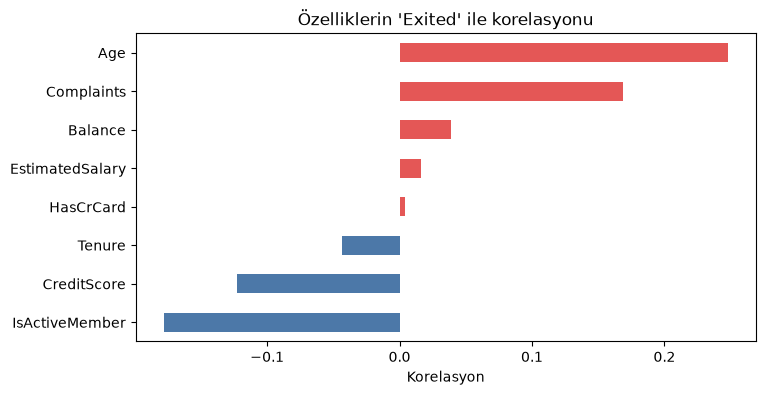

IsActiveMember    -0.178
CreditScore       -0.122
Tenure            -0.043
HasCrCard          0.004
EstimatedSalary    0.016
Balance            0.039
Complaints         0.169
Age                0.248
Name: Exited, dtype: float64

In [9]:
cols = NUMERIC_FEATURES + BINARY_FEATURES
corr = df[cols + ["Exited"]].corr()["Exited"].drop("Exited").sort_values()
ax = corr.plot(kind="barh", color=["#E45756" if v > 0 else "#4C78A8" for v in corr])
ax.set_title("Özelliklerin 'Exited' ile korelasyonu")
ax.set_xlabel("Korelasyon")
plt.show()
corr.round(3)

Korelasyon yalnızca **doğrusal** ilişkiyi ölçer. Ürün sayısı gibi doğrusal olmayan etkileri yakalayamaz. Bu yüzden ağaç tabanlı modeller (Decision Tree, Random Forest, Gradient Boosting) bu veride Logistic Regression'a göre avantajlı olabilir. Aşama 4'te bunu karşılaştıracağız.

## 7. Ön işleme: bölme ve dönüşüm (sızıntısız)

Sıra çok önemlidir:
1. Önce veriyi **eğitim / test** olarak böl (sınıf oranını koruyarak).
2. Ön işleme nesnesini **sadece eğitim verisine** `fit` et. Medyan, ortalama, standart sapma ve kategori listesi yalnızca eğitimden öğrenilir.
3. Aynı nesneyi teste sadece `transform` ile uygula.

Test verisinin istatistikleri eğitime karışırsa model fazla iyi görünür. Buna **veri sızıntısı** denir.

In [10]:
X_train, X_test, y_train, y_test = split_data(df)
print("Eğitim:", X_train.shape, "| Test:", X_test.shape)
print(f"Churn oranı -> eğitim: {y_train.mean():.3f}, test: {y_test.mean():.3f}  (stratify sayesinde neredeyse aynı)")

preprocessor = build_preprocessor()
X_train_t = preprocessor.fit_transform(X_train)   # yalnızca eğitime fit
X_test_t = preprocessor.transform(X_test)         # teste sadece uygula

feature_names = get_feature_names(preprocessor)
print("Dönüşüm sonrası eğitim şekli:", X_train_t.shape)
print("Özellik sayısı:", len(feature_names))

Eğitim: (7980, 11) | Test: (1995, 11)
Churn oranı -> eğitim: 0.199, test: 0.198  (stratify sayesinde neredeyse aynı)
Dönüşüm sonrası eğitim şekli: (7980, 21)
Özellik sayısı: 21


In [11]:
# Dönüşmüş verinin ilk 5 satırı
pd.DataFrame(X_train_t, columns=feature_names).head().round(2)

,Age,CreditScore,Tenure,Balance,EstimatedSalary,Complaints,Gender_Female,Gender_Male,Geography_Akdeniz,Geography_Dogu Anadolu,Geography_Ege,Geography_Guneydogu Anadolu,Geography_Ic Anadolu,Geography_Karadeniz,Geography_Marmara,NumOfProducts_1,NumOfProducts_2,NumOfProducts_3,NumOfProducts_4,HasCrCard,IsActiveMember
0,-0.82,0.04,-1.26,-0.12,0.26,-0.63,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,-0.09,1.25,1.26,-0.17,-1.10,-0.63,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0
2,0.10,0.33,-0.63,1.91,-0.39,0.89,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,2.31,-1.04,0.95,-1.34,-0.01,-0.63,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.74,0.27,1.26,0.94,0.28,-0.63,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [12]:
# Eğitim verisinden öğrenilen değerler (ör. imputer medyanları ve ölçekleyici ortalamaları)
num_pipe = preprocessor.named_transformers_["num"]
learned = pd.DataFrame({
    "medyan (eksik doldurma)": num_pipe["imputer"].statistics_,
    "ortalama (ölçekleme)": num_pipe["scaler"].mean_,
    "std (ölçekleme)": num_pipe["scaler"].scale_,
}, index=NUMERIC_FEATURES)
learned.round(2)

,medyan (eksik doldurma),ortalama (ölçekleme),std (ölçekleme)
Age,40.00,39.94,10.85
CreditScore,649.00,648.63,89.08
Tenure,5.00,4.99,3.17
Balance,81641.98,74565.72,55451.43
EstimatedSalary,110511.98,110516.02,51931.05
Complaints,0.00,0.42,0.66


## Özet

- 10.000 satırdan 25 tekrar kayıt silindi → **9.975 müşteri**.
- Eksik değerler (`Geography`, `CreditScore`, `EstimatedSalary`) Pipeline içinde, eğitimden öğrenilen medyan / en sık değerle dolduruluyor.
- Sınıf dengesiz (~%20 ayrılan) → Accuracy yerine **Recall, F1, ROC-AUC** öncelikli; eğitimde `class_weight='balanced'`.
- Yaş, ürün sayısı, aktiflik ve şikayet sayısı en belirgin sinyaller.
- Ön işleme sonrası **21 özellik** üretildi. Sızıntı yok.

**Sonraki adım:** Aşama 4, dört modelin eğitimi ve karşılaştırılması.